Logistic Regression:


Contributions:
1. https://www.ibm.com/think/topics/logistic-regression
2. https://www.analyticsvidhya.com/blog/2023/01/a-comprehensive-guide-to-ols-regression-part-1/

In [1]:
# Libraries:
import json
import pickle
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

from itertools import combinations
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import BaseCrossValidator, ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, classification_report, accuracy_score,
    f1_score, recall_score, precision_score, log_loss, average_precision_score,
    roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
)

In [2]:
# ============================================
# Paths & factor pairs
# ============================================
# Alternate machine path (SARB laptop):
# BASE_DIR = Path('C:/Users/p528552/OneDrive - South African Reserve Bank/Documents/1. MEng - Data Science/1. Project_2025/Data/factor_timing/legacy')
BASE_DIR = Path('C:/Users/ccwis/OneDrive/Documents/1. MEng - Data Science/Project/factor_timing/legacy')

DATA_DIR = BASE_DIR / 'data_input'
OUTPUT_DIR = BASE_DIR / 'results' / 'model_outputs'
PROBS_DIR = OUTPUT_DIR / 'probs'
ARTIFACT_DIR = OUTPUT_DIR / 'artifacts'
SHAP_DIR = OUTPUT_DIR / 'shap'
METRICS_PATH = OUTPUT_DIR / 'metrics_summary.csv'

for _dir in (PROBS_DIR, ARTIFACT_DIR, SHAP_DIR):
    _dir.mkdir(parents=True, exist_ok=True)

# Every factor pair this pipeline runs for a given model.
FACTOR_PAIRS = ['Momentum_vs_Value', 'Momentum_vs_Quality', 'Value_vs_Quality']

In [3]:
# ============================================
# Data loading (parameterized by factor pair)
# ============================================
def load_data(pair):
    df_factor = pd.read_csv(DATA_DIR / 'labeled_relative_factor_returns.csv', parse_dates=['Date'])
    df_factor = df_factor[['Date', f'{pair}_trend']]
    df_factor = df_factor.set_index('Date')

    df = pd.read_csv(DATA_DIR / 'lagged_data.csv', parse_dates=['Date'])
    df = df.set_index('Date')

    data = pd.concat([df, df_factor], axis=1, join='inner')
    # Trend scanning needs returns out to t+10, so the final ~10 dates have
    # no computable label. ffill() would manufacture them from the last known
    # label, putting fabricated targets inside the OOS block -- drop instead.
    data = data.dropna(subset=[f'{pair}_trend'])
    # Unified missing-value policy across all three models.
    return data.ffill().bfill()

In [4]:
# ============================================
# Model: elastic-net logistic regression (scikit-learn)
# ============================================
# Objective: mean log-loss + (lambda/m) * [alpha*|b|_1 + (1-alpha)/2 * |b|_2^2],
# which is scikit-learn's elastic net with C = 1/lambda and l1_ratio = alpha.
# Both alpha (the L1/L2 mix) and lambda (the strength) are tuned in the CPCV
# grid. saga is the scikit-learn solver that supports the elastic-net penalty.
SOLVER_TOL = 1e-6
SOLVER_MAX_ITER = 100_000

def make_model(alpha, lambda_reg):
    return LogisticRegression(
        penalty="elasticnet", solver="saga", l1_ratio=alpha, C=1.0 / lambda_reg,
        tol=SOLVER_TOL, max_iter=SOLVER_MAX_ITER, random_state=0,
    )

In [5]:
# ============================================================
# Combinatorial Purged Cross-Validation (CPCV)
# ============================================================
CV_SPLITS = 5
CV_TEST_SPLITS = 2       # C(5,2) = 10 folds. k=1 collapsed CPCV to plain
                         # 5-fold purged CV with one backtest path.
PURGE_GAP = 12
FINAL_TEST_POINTS = 156   # 3 years of unseen data

# ===========================================================
# CPCV Splitter
# ===========================================================
class CombinatorialPurgedCV(BaseCrossValidator):
    """Purged Combinatorial Cross-Validation (De Prado style)."""
    def __init__(self, n_splits=CV_SPLITS, n_test_splits=CV_TEST_SPLITS, purge_gap=PURGE_GAP):
        self.n_splits = n_splits
        self.n_test_splits = n_test_splits
        self.purge_gap = purge_gap

    def split(self, X, y=None, groups=None):
        n_samples = len(X)
        fold_size = n_samples // self.n_splits
        indices = np.arange(n_samples)

        fold_boundaries = [(i * fold_size, (i + 1) * fold_size) for i in range(self.n_splits)]
        fold_boundaries[-1] = (fold_boundaries[-1][0], n_samples)

        for test_folds in combinations(range(self.n_splits), self.n_test_splits):
            test_mask = np.zeros(n_samples, dtype=bool)
            for f in test_folds:
                s, e = fold_boundaries[f]
                test_mask[s:e] = True

            train_mask = ~test_mask
            for f in test_folds:
                s, e = fold_boundaries[f]
                train_mask[max(0, s - self.purge_gap): s] = False
                train_mask[e: min(n_samples, e + self.purge_gap)] = False

            yield indices[train_mask], indices[test_mask]

    def get_n_splits(self, X=None, y=None, groups=None):
        from math import comb
        return comb(self.n_splits, self.n_test_splits)

    def group_bounds(self, n_samples):
        """(start, end) of each chronological group; the last takes the remainder."""
        size = n_samples // self.n_splits
        bounds = [(i * size, (i + 1) * size) for i in range(self.n_splits)]
        bounds[-1] = (bounds[-1][0], n_samples)
        return bounds

    def backtest_paths(self):
        """For each back-test path, the split whose held-out predictions supply each group.

        Every group is held out in C(N-1, k-1) splits; path j takes the j-th of them in
        split order, giving phi[N, k] = C(N-1, k-1) paths, each covering the whole sample
        out of sample (Lopez de Prado, 2018, ch. 12).
        """
        splits = list(combinations(range(self.n_splits), self.n_test_splits))
        holding = [[sp for sp, test in enumerate(splits) if g in test] for g in range(self.n_splits)]
        return [[holding[g][j] for g in range(self.n_splits)] for j in range(len(holding[0]))]


def held_out_vector(n_samples, test_idx, probs):
    """Full-length vector with a split's held-out probabilities in place, NaN elsewhere."""
    out = np.full(n_samples, np.nan)
    out[test_idx] = probs
    return out


def path_aucs(cv, y, split_probs):
    """ROC-AUC of every back-test path, assembled from the splits' held-out predictions."""
    bounds = cv.group_bounds(len(y))
    aucs = []
    for path in cv.backtest_paths():
        pred = np.full(len(y), np.nan)
        for group, split_no in enumerate(path):
            start, end = bounds[group]
            pred[start:end] = split_probs[split_no][start:end]
        assert not np.isnan(pred).any(), "a back-test path is missing held-out predictions"
        aucs.append(roc_auc_score(y, pred))
    return aucs

In [6]:
def tune_hyperparameters(X, y, return_grid=False, verbose=True):
    cv = CombinatorialPurgedCV()

    # alpha mixes the penalties (0 = ridge/L2, 1 = lasso/L1); lambda_reg sets
    # the overall strength (C = 1/lambda_reg). lambda_reg spans 0.01-1000: an
    # earlier cap at 0.1 was selected at the ceiling on all 3 pairs. 18 configs.
    param_grid = {
        "alpha": [0.0, 0.5, 1.0],
        "lambda_reg": [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0],
    }

    best_score, best_params = -np.inf, None
    rows = []

    if verbose:
        print(f"Testing {len(ParameterGrid(param_grid))} parameter combinations...")

    for params in ParameterGrid(param_grid):
        fold_aucs, split_probs = [], []

        for train_idx, test_idx in cv.split(X, y):
            model = make_model(**params)
            model.fit(X[train_idx], y[train_idx])

            y_score = model.predict_proba(X[test_idx])[:, 1]
            auc = roc_auc_score(y[test_idx], y_score)
            fold_aucs.append(float(auc))
            split_probs.append(held_out_vector(len(y), test_idx, y_score))

        # Selection score: mean ROC-AUC over the ten splits. The back-test
        # paths pool predictions from models fitted on different groups, and
        # holding a group out moves the training base rate against that
        # group's own, so an intercept-only model scores about 0.44 on the
        # paths. Path AUCs are recorded for reporting, not used for selection.
        mean_auc = np.mean(fold_aucs)
        std_auc = np.std(fold_aucs, ddof=1)
        p_aucs = path_aucs(cv, y, split_probs)

        rows.append({
            **params,
            "mean_auc": mean_auc,            # mean split AUC (selection score)
            "std_auc": std_auc,
            "min_auc": np.min(fold_aucs),
            "max_auc": np.max(fold_aucs),
            "fold_aucs": fold_aucs,
            "mean_path_auc": np.mean(p_aucs),
            "path_aucs": p_aucs              # back-test path AUCs (reporting)
        })

        if mean_auc > best_score:
            best_score, best_params = mean_auc, params
            if verbose:
                print(f"New best params: {best_params} (AUC: {best_score:.3f})")

    grid_df = pd.DataFrame(rows).sort_values("mean_auc", ascending=False)

    if verbose:
        print("\n=== Top 5 Parameter Combinations ===")
        for _, r in grid_df.head(5).iterrows():
            print(f"Score: {r['mean_auc']:.3f} | Params: {best_params}")

    if return_grid:
        return best_params, grid_df
    return best_params

In [7]:
def window_signature(X):
    """
    Create a stable, compact signature for a rolling window
    based on its mean and std across features.
    """
    import hashlib
    stats = np.concatenate([X.mean(axis=0), X.std(axis=0)])
    stats_bytes = stats.tobytes()
    return hashlib.sha1(stats_bytes).hexdigest()

In [8]:
def save_artifact(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    if isinstance(obj, pd.DataFrame):
        obj.to_csv(path, index=False)
    elif path.suffix == ".json":
        with open(path, "w") as f:
            json.dump(obj, f, indent=2)
    else:
        with open(path, "wb") as f:
            pickle.dump(obj, f)

In [9]:
def walk_forward_validation(
    X, y, n_test, base_params,
    retune_every=52, lookback=None,  # None = expanding window
    selections=None                  # list that records each retuned parameter set
):
    actuals, predictions, probabilities = [], [], []
    current_params = base_params.copy()

    hyperparam_cache = {}

    print(f"\nRunning Rolling-Window WFV with Hyperparameter Caching...")
    print(f"Training window = {lookback if lookback else 'expanding (all history)'}")

    for i in tqdm(range(n_test)):
        train_size = len(X) - n_test + i
        if train_size <= 0:
            continue

        # ===== Purge gap =====
        # Trend-scanning labels (span=(1,12)) resolve using returns out to
        # t+10, so training rows within PURGE_GAP of the test point have
        # labels computed from the test period itself. Drop them.
        train_end = train_size - PURGE_GAP
        if train_end <= 0:
            continue

        # Expanding window: train on all history up to the purged end.
        # (lookback=None). Set lookback to an int for a fixed rolling window.
        start = 0 if lookback is None else max(0, train_end - lookback)
        X_train = X[start:train_end]
        y_train = y[start:train_end]
        X_test  = X[train_size:train_size+1]
        y_test  = y[train_size:train_size+1]

        # === Scaling: fit on the training window only ===
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test  = scaler.transform(X_test)

        # === Adaptive tuning with caching ===
        if retune_every and i > 0 and i % retune_every == 0:

            # create stable signature of training window
            sig = window_signature(X_train)

            if sig in hyperparam_cache:
                print(f"\nReusing cached params at step {i}")
                current_params = hyperparam_cache[sig]

            else:
                print(f"\n--- Retuning at step {i} ---")
                current_params = tune_hyperparameters(X_train, y_train)

                hyperparam_cache[sig] = current_params

            if selections is not None:
                selections.append({"from_step": i, "n_train": len(y_train), **current_params})

        # Train model
        model = make_model(**current_params)
        model.fit(X_train, y_train)

        # Predict (fixed 0.5 threshold)
        y_prob = model.predict_proba(X_test)[:, 1]
        y_pred = (y_prob >= 0.5).astype(int)

        predictions.append(y_pred[0])
        actuals.append(y_test[0])
        probabilities.append(y_prob[0])

    print("\n=== Final Evaluation Results ===")
    print(classification_report(actuals, predictions))
    return (
        np.array(actuals),
        np.array(predictions),
        np.array(probabilities)
    )

In [10]:
# ===========================================================
# Results: metrics + diagnostic plots for one walk-forward run
# ===========================================================
def display_walkforward_results(y_true, y_pred, y_proba, pair_label=""):
    acc  = accuracy_score(y_true, y_pred)
    f1   = f1_score(y_true, y_pred)
    rec  = recall_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)

    auc    = roc_auc_score(y_true, y_proba)
    pr_auc = average_precision_score(y_true, y_proba)

    y_proba_clipped = np.clip(y_proba, 1e-12, 1 - 1e-12)
    ll = log_loss(y_true, y_proba_clipped)

    print(f"Walk-forward Performance [{pair_label}]:")
    print(f"Accuracy : {acc:.3f}")
    print(f"F1 Score : {f1:.3f}")
    print(f"Recall   : {rec:.3f}")
    print(f"Precision: {prec:.3f}")
    print(f"ROC AUC  : {auc:.3f}")
    print(f"PR  AUC  : {pr_auc:.3f}")
    print(f"Log Loss : {ll:.3f}")

    # --- Graphs ---
    plt.figure(figsize=(12,5))
    plt.plot(y_true, label="True", marker="o",linestyle='None')
    plt.plot(y_pred, label="Predicted", marker="x",linestyle='None')
    plt.plot(y_proba,label="Probability",linestyle='--', alpha=0.5)
    plt.title(f"Walk-forward Predictions vs True Values [{pair_label}]")
    plt.legend()
    plt.show()

    fpr, tpr, _ = roc_curve(y_true, y_proba)
    plt.figure(figsize=(6,6))
    plt.plot(fpr, tpr, label=f"ROC (AUC={auc:.3f})")
    plt.plot([0,1],[0,1], '--', color='gray')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve [{pair_label}]")
    plt.legend()
    plt.show()

    precs, recs, _ = precision_recall_curve(y_true, y_proba)
    plt.figure(figsize=(6,6))
    plt.plot(recs, precs, label=f"PR (AP={pr_auc:.3f})", color="purple")
    plt.title(f"Precision-Recall Curve [{pair_label}]")
    plt.legend()
    plt.show()

    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm).plot(cmap="Blues")
    plt.title(f"Confusion Matrix [{pair_label}]")
    plt.show()

    return {
        "accuracy": acc, "f1": f1, "recall": rec, "precision": prec,
        "roc_auc": auc, "pr_auc": pr_auc, "log_loss": ll,
    }

In [11]:
# ============================================
# Metrics summary — single source of truth for the write-up.
# Re-running a pair updates its row instead of duplicating it.
# ============================================
def append_metrics_row(row):
    row = {"timestamp": datetime.now(timezone.utc).isoformat(), **row}
    new_row = pd.DataFrame([row])
    if METRICS_PATH.exists():
        existing = pd.read_csv(METRICS_PATH)
        existing = existing[~(
            (existing["model"] == row["model"]) & (existing["factor_pair"] == row["factor_pair"])
        )]
        combined = pd.concat([existing, new_row], ignore_index=True)
    else:
        combined = new_row
    combined.to_csv(METRICS_PATH, index=False)

In [12]:
# ============================================
# SHAP (linear model, log-odds contributions)
# ============================================
def compute_shap_importance(data, best_params, feature_names, n_test):
    import shap

    X = data.iloc[:, :-1].values
    y = data.iloc[:, -1].values
    X = np.nan_to_num(X, nan=np.nan, posinf=1e10, neginf=-1e10)

    train_end = len(X) - n_test
    X_train = X[:train_end]
    y_train = y[:train_end]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)

    model = make_model(**best_params)
    model.fit(X_train_scaled, y_train)

    betas = model.coef_[0]
    intercept = model.intercept_[0]

    # phi_ij = (x_ij - E[x_j]) * beta_j -- SHAP-consistent contributions in log-odds space
    x_mean = X_train_scaled.mean(axis=0)
    phi = (X_train_scaled - x_mean) * betas
    expected_value = intercept + np.dot(x_mean, betas)

    importance = pd.Series(
        np.abs(phi).mean(axis=0),
        index=feature_names
    ).sort_values(ascending=False)

    # Sanity check: contributions should reconstruct the model's own raw score.
    z_recon = expected_value + phi.sum(axis=1)
    z_model = model.decision_function(X_train_scaled)
    print(f"Max |reconstruction error|: {np.max(np.abs(z_recon - z_model)):.2e}")

    exp = shap.Explanation(
        values=phi,
        base_values=np.full(phi.shape[0], expected_value),
        data=X_train_scaled,
        feature_names=feature_names,
    )
    return importance, exp, X_train_scaled

In [13]:
# ============================================
# Full pipeline for one factor pair
# ============================================
def run_pipeline(pair):
    pair_slug = pair.lower()
    print(f"\n{'='*60}\nFACTOR PAIR: {pair}\n{'='*60}")

    data = load_data(pair)

    X = data.iloc[:, :-1].values
    y = data.iloc[:, -1].values
    feature_names = data.columns[:-1].tolist()

    X = np.nan_to_num(X, nan=np.nan, posinf=1e10, neginf=-1e10)

    print("=== PHASE 1: HYPERPARAMETER TUNING ===")
    # Tune on pre-test data only, with the scaler also fit on pre-test
    # data only. Fitting either on the full sample leaks the OOS block's
    # mean/variance and labels into model selection.
    X_train_full = X[:-FINAL_TEST_POINTS]
    y_train_full = y[:-FINAL_TEST_POINTS]
    X_train_full_scaled = StandardScaler().fit_transform(X_train_full)
    best_params, tuning_grid = tune_hyperparameters(
        X_train_full_scaled, y_train_full, return_grid=True)
    save_artifact(tuning_grid, ARTIFACT_DIR / f"logistic_{pair_slug}_tuning_grid.pkl")
    save_artifact(best_params, ARTIFACT_DIR / f"logistic_{pair_slug}_best_params.json")

    print("\n=== PHASE 2: ADAPTIVE WALK-FORWARD ===")
    # Unscaled X: walk_forward_validation refits the scaler per window.
    selections = [{"from_step": 0, "n_train": len(y_train_full), **best_params}]
    actuals, preds, probs = walk_forward_validation(
        X, y,
        n_test=FINAL_TEST_POINTS,
        base_params=best_params,
        retune_every=52,
        selections=selections
    )
    save_artifact(selections, ARTIFACT_DIR / f"logistic_{pair_slug}_walkforward_params.json")

    metrics = display_walkforward_results(actuals, preds, probs, pair_label=pair)

    df_probs = pd.DataFrame({
        "Date": data.index[-len(probs):],
        "actual": actuals,
        "prediction": preds,
        "probability": probs,
    }).set_index("Date")
    df_probs.to_csv(PROBS_DIR / f"logistic_{pair_slug}_probs.csv", index=True)

    shap_importance, shap_exp, X_train_scaled = compute_shap_importance(
        data, best_params, feature_names, FINAL_TEST_POINTS
    )
    shap_importance.head(20).to_csv(SHAP_DIR / f"logistic_{pair_slug}_shap.csv", index=True)

    append_metrics_row({
        "model": "Logistic",
        "factor_pair": pair,
        "n_test": FINAL_TEST_POINTS,
        **metrics,
        "best_params": json.dumps(best_params),
    })

    return {
        "pair": pair,
        "best_params": best_params,
        "tuning_grid": tuning_grid,
        "feature_names": feature_names,
        "adaptive": (actuals, preds, probs),
        "shap_importance": shap_importance,
        "shap_explanation": shap_exp,
        "X_train_scaled": X_train_scaled,
    }

In [14]:
def plot_pair_diagnostics(result):
    import shap

    pair = result["pair"]
    tuning_grid = result["tuning_grid"]

    plt.figure(figsize=(6,4))
    plt.hist(tuning_grid["mean_auc"], bins=25)
    plt.xlabel("CPCV Mean ROC-AUC")
    plt.ylabel("Frequency")
    plt.title(f"Logistic: ROC-AUC Distribution Across Hyperparameters [{pair}]")
    plt.tight_layout()
    plt.show()

    top10 = tuning_grid.head(10)
    fold_data = top10["fold_aucs"].tolist()
    plt.figure(figsize=(6,4))
    plt.boxplot(fold_data)
    plt.xlabel("Top 10 Parameter Sets")
    plt.ylabel("Fold ROC-AUC")
    plt.title(f"CPCV Fold Stability (Top 10 Logistic Models) [{pair}]")
    plt.tight_layout()
    plt.show()

    shap.summary_plot(
        result["shap_explanation"], result["X_train_scaled"],
        feature_names=result["feature_names"], plot_type="dot", show=True
    )


FACTOR PAIR: Momentum_vs_Value
=== PHASE 1: HYPERPARAMETER TUNING ===
Testing 18 parameter combinations...


New best params: {'alpha': 0.0, 'lambda_reg': 0.01} (AUC: 0.519)


New best params: {'alpha': 0.0, 'lambda_reg': 0.1} (AUC: 0.522)


New best params: {'alpha': 0.0, 'lambda_reg': 1000.0} (AUC: 0.541)



=== Top 5 Parameter Combinations ===
Score: 0.541 | Params: {'alpha': 0.0, 'lambda_reg': 1000.0}
Score: 0.522 | Params: {'alpha': 0.0, 'lambda_reg': 1000.0}
Score: 0.521 | Params: {'alpha': 0.0, 'lambda_reg': 1000.0}
Score: 0.521 | Params: {'alpha': 0.0, 'lambda_reg': 1000.0}
Score: 0.520 | Params: {'alpha': 0.0, 'lambda_reg': 1000.0}

=== PHASE 2: ADAPTIVE WALK-FORWARD ===

Running Rolling-Window WFV with Hyperparameter Caching...
Training window = expanding (all history)


  0%|          | 0/156 [00:00<?, ?it/s]

... (58 outputs left out)

 92%|█████████▏| 144/156 [13:09<00:25,  2.13s/it]

 97%|█████████▋| 151/156 [13:10<00:07,  1.44s/it]

100%|██████████| 156/156 [13:10<00:00,  5.07s/it]


=== Final Evaluation Results ===
              precision    recall  f1-score   support

         0.0       0.43      0.28      0.34        71
         1.0       0.54      0.69      0.61        85

    accuracy                           0.51       156
   macro avg       0.49      0.49      0.47       156
weighted avg       0.49      0.51      0.49       156

Walk-forward Performance [Momentum_vs_Value]:
Accuracy : 0.506
F1 Score : 0.605
Recall   : 0.694
Precision: 0.536
ROC AUC  : 0.577
PR  AUC  : 0.638
Log Loss : 0.683


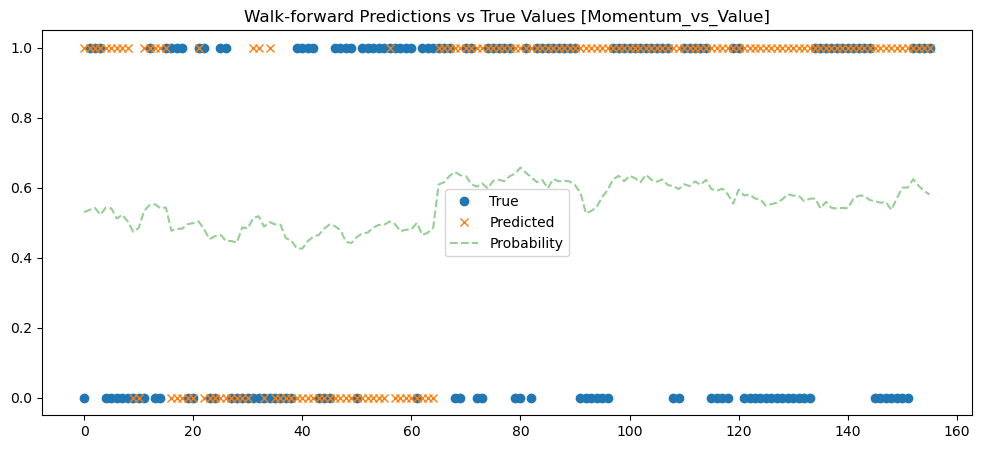

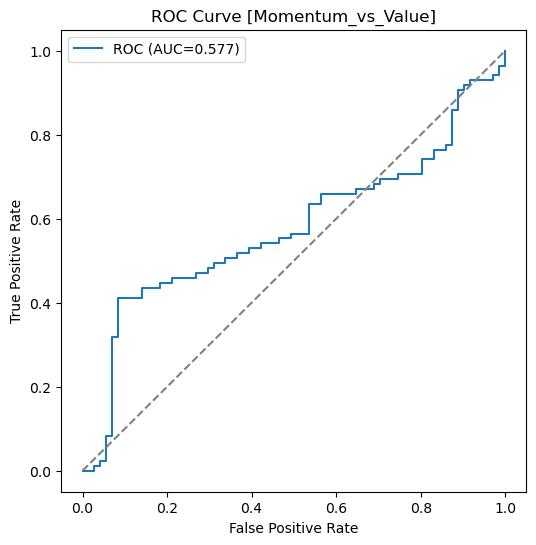

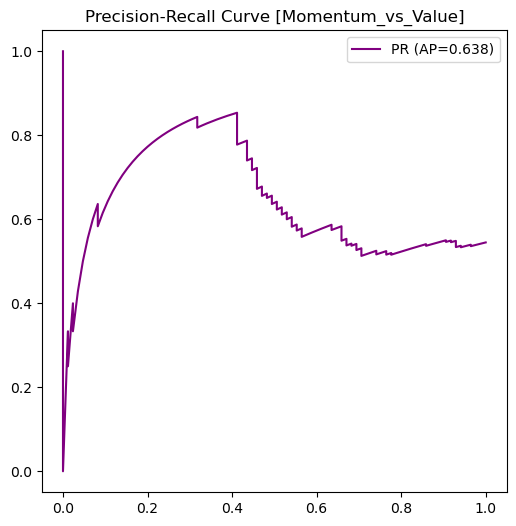

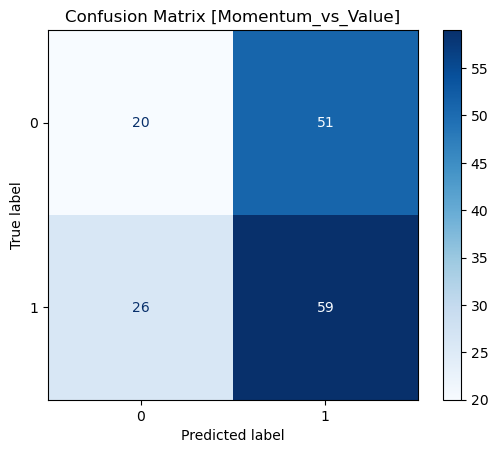

Max |reconstruction error|: 2.22e-16


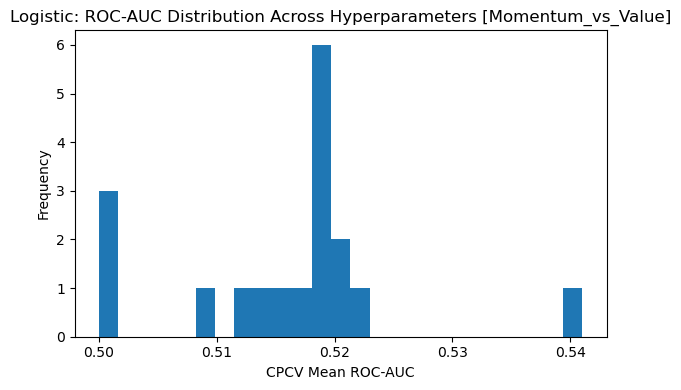

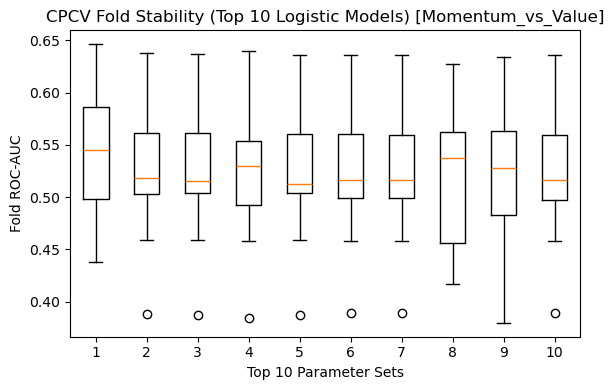

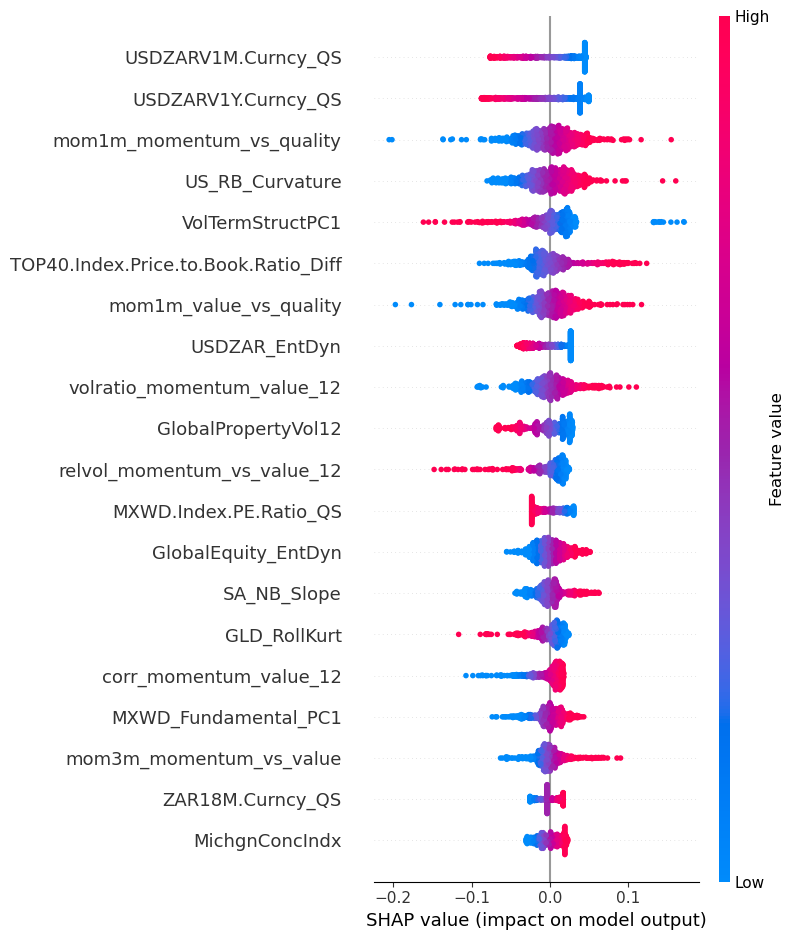


FACTOR PAIR: Momentum_vs_Quality
=== PHASE 1: HYPERPARAMETER TUNING ===
Testing 18 parameter combinations...


New best params: {'alpha': 0.0, 'lambda_reg': 0.01} (AUC: 0.485)


New best params: {'alpha': 0.0, 'lambda_reg': 0.1} (AUC: 0.485)


New best params: {'alpha': 0.0, 'lambda_reg': 1.0} (AUC: 0.489)


New best params: {'alpha': 0.0, 'lambda_reg': 10.0} (AUC: 0.502)
New best params: {'alpha': 0.0, 'lambda_reg': 100.0} (AUC: 0.521)


New best params: {'alpha': 0.0, 'lambda_reg': 1000.0} (AUC: 0.531)


... (38 outputs left out)

 93%|█████████▎| 145/156 [04:13<00:09,  1.22it/s]

 98%|█████████▊| 153/156 [04:13<00:01,  1.78it/s]

100%|██████████| 156/156 [04:13<00:00,  1.63s/it]


=== Final Evaluation Results ===
              precision    recall  f1-score   support

         0.0       0.55      0.41      0.47        73
         1.0       0.57      0.70      0.63        83

    accuracy                           0.56       156
   macro avg       0.56      0.55      0.55       156
weighted avg       0.56      0.56      0.55       156

Walk-forward Performance [Momentum_vs_Quality]:
Accuracy : 0.564
F1 Score : 0.630
Recall   : 0.699
Precision: 0.574
ROC AUC  : 0.602
PR  AUC  : 0.602
Log Loss : 0.680


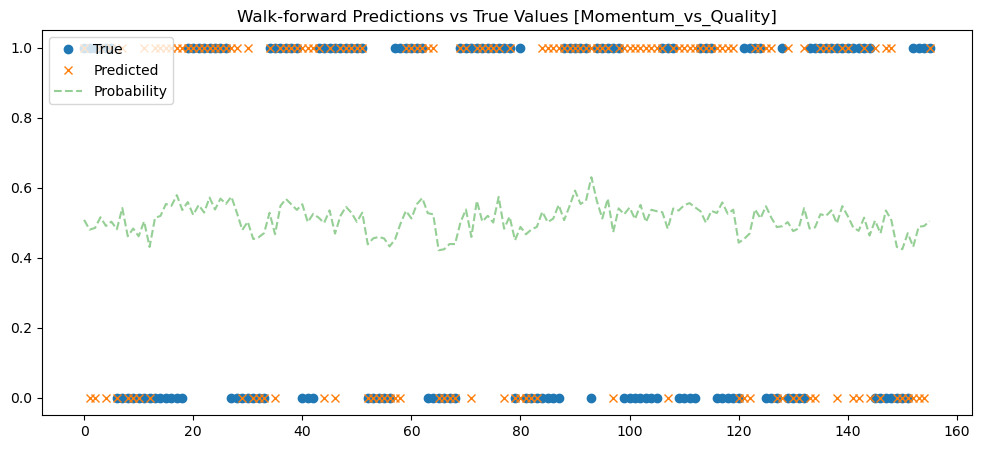

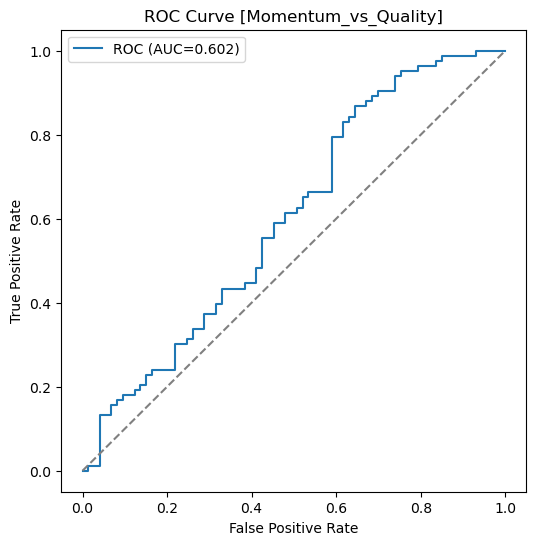

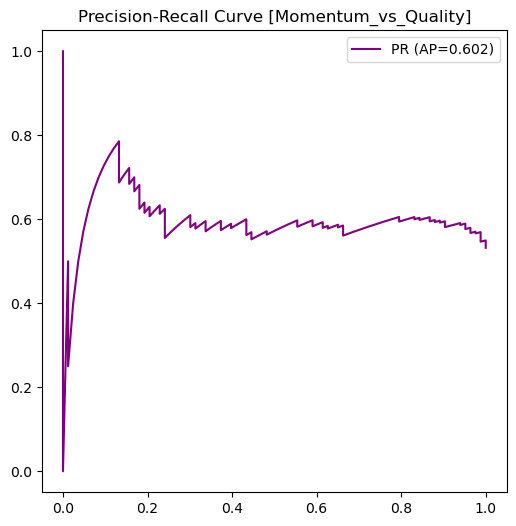

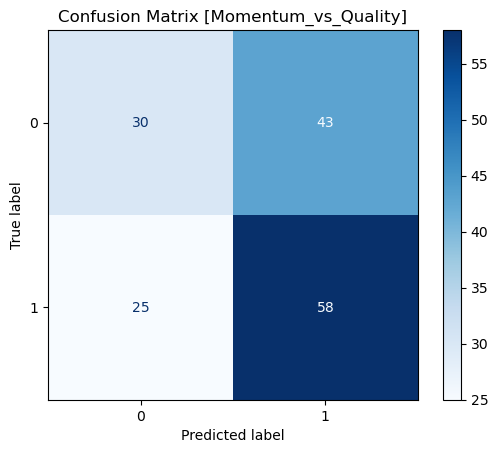

Max |reconstruction error|: 1.39e-16


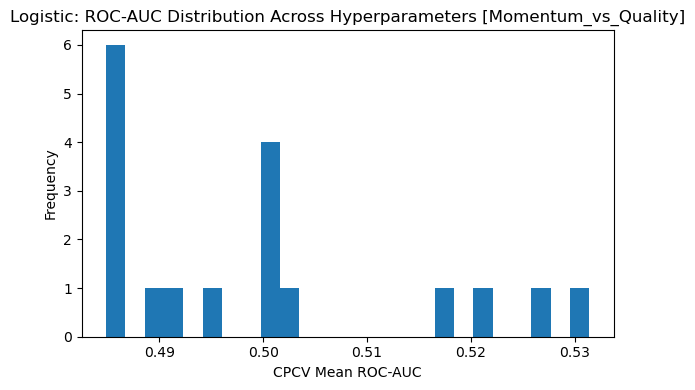

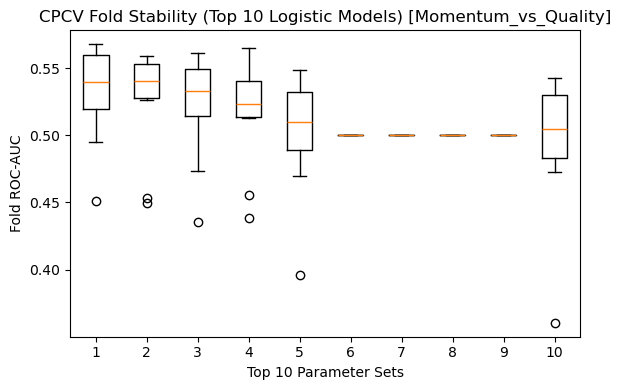

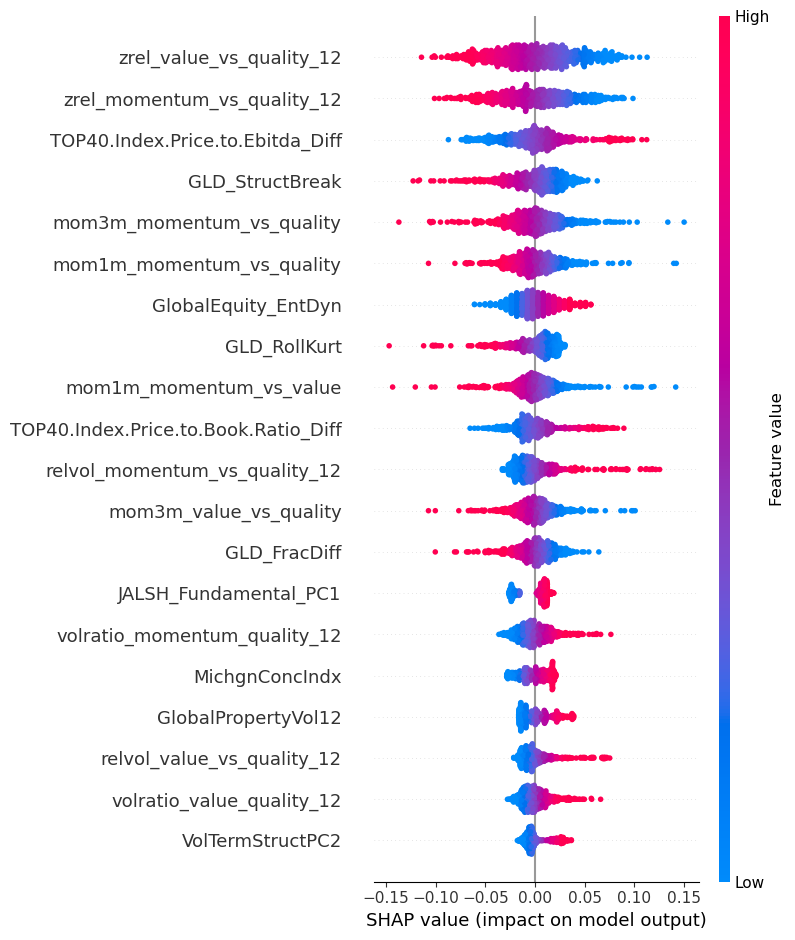


FACTOR PAIR: Value_vs_Quality
=== PHASE 1: HYPERPARAMETER TUNING ===
Testing 18 parameter combinations...


New best params: {'alpha': 0.0, 'lambda_reg': 0.01} (AUC: 0.505)


New best params: {'alpha': 0.0, 'lambda_reg': 100.0} (AUC: 0.517)
New best params: {'alpha': 0.0, 'lambda_reg': 1000.0} (AUC: 0.530)


New best params: {'alpha': 1.0, 'lambda_reg': 10.0} (AUC: 0.531)

=== Top 5 Parameter Combinations ===
Score: 0.531 | Params: {'alpha': 1.0, 'lambda_reg': 10.0}
Score: 0.530 | Params: {'alpha': 1.0, 'lambda_reg': 10.0}
Score: 0.517 | Params: {'alpha': 1.0, 'lambda_reg': 10.0}
Score: 0.517 | Params: {'alpha': 1.0, 'lambda_reg': 10.0}
Score: 0.506 | Params: {'alpha': 1.0, 'lambda_reg': 10.0}

=== PHASE 2: ADAPTIVE WALK-FORWARD ===

Running Rolling-Window WFV with Hyperparameter Caching...
Training window = expanding (all history)


  0%|          | 0/156 [00:00<?, ?it/s]

  1%|▏         | 2/156 [00:00<00:09, 16.05it/s]

... (85 outputs left out)

 93%|█████████▎| 145/156 [04:28<00:07,  1.42it/s]

 98%|█████████▊| 153/156 [04:28<00:01,  2.21it/s]

100%|██████████| 156/156 [04:28<00:00,  1.72s/it]


=== Final Evaluation Results ===
              precision    recall  f1-score   support

         0.0       0.59      0.54      0.56        82
         1.0       0.54      0.59      0.56        74

    accuracy                           0.56       156
   macro avg       0.57      0.57      0.56       156
weighted avg       0.57      0.56      0.56       156

Walk-forward Performance [Value_vs_Quality]:
Accuracy : 0.564
F1 Score : 0.564
Recall   : 0.595
Precision: 0.537
ROC AUC  : 0.586
PR  AUC  : 0.578
Log Loss : 0.685


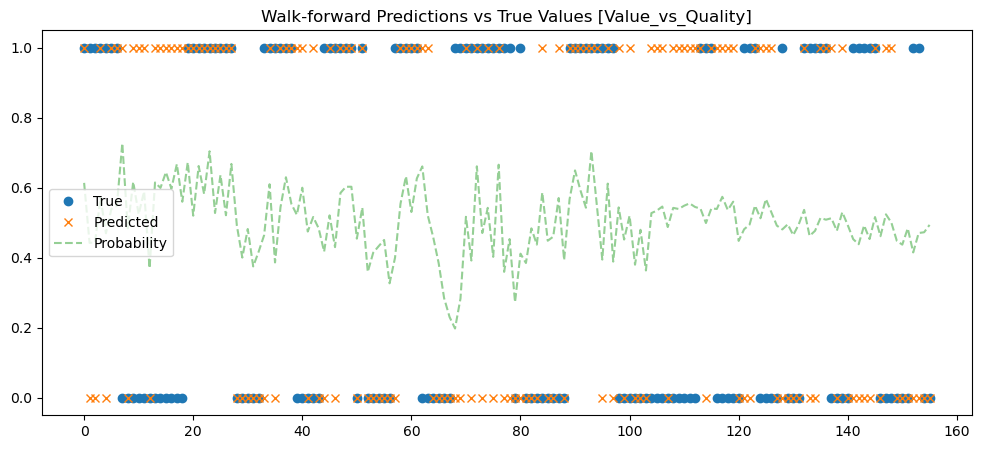

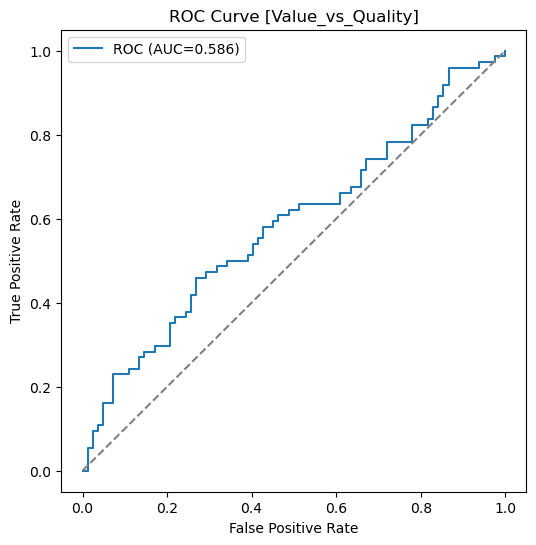

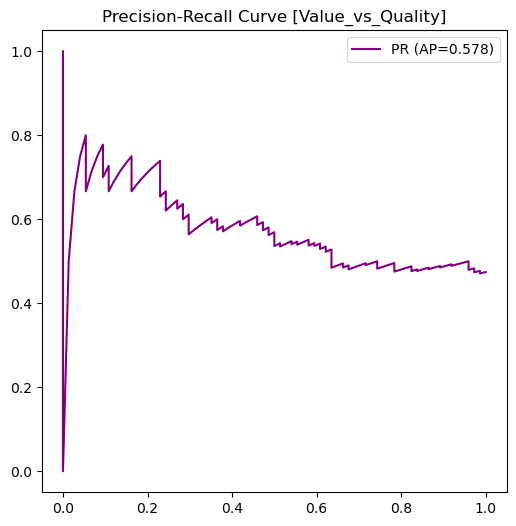

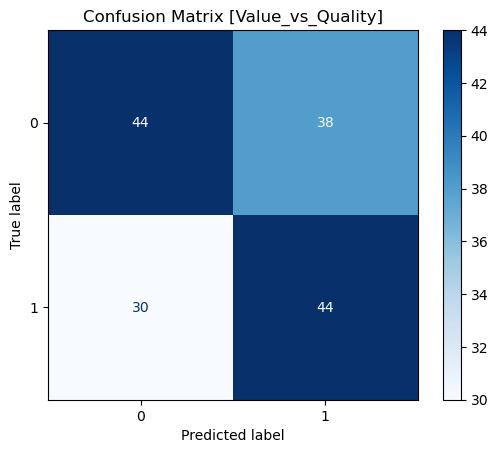

Max |reconstruction error|: 3.33e-16


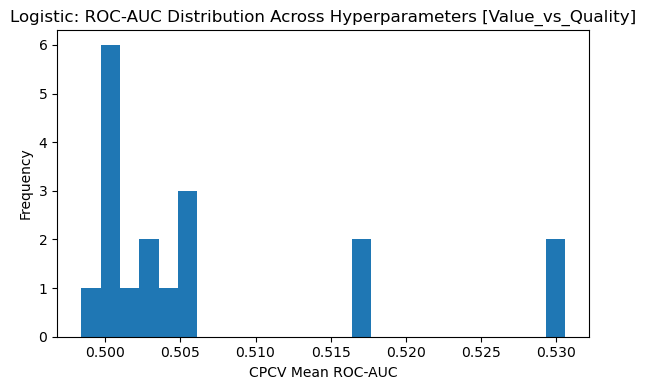

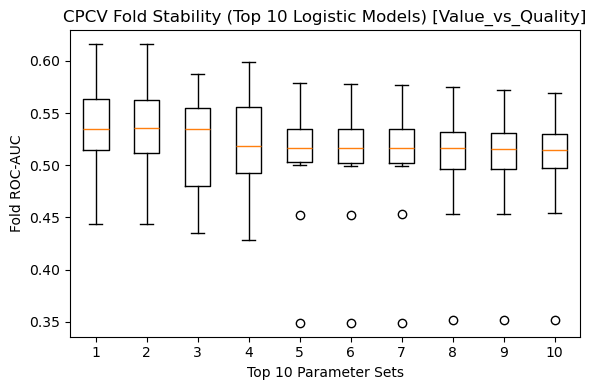

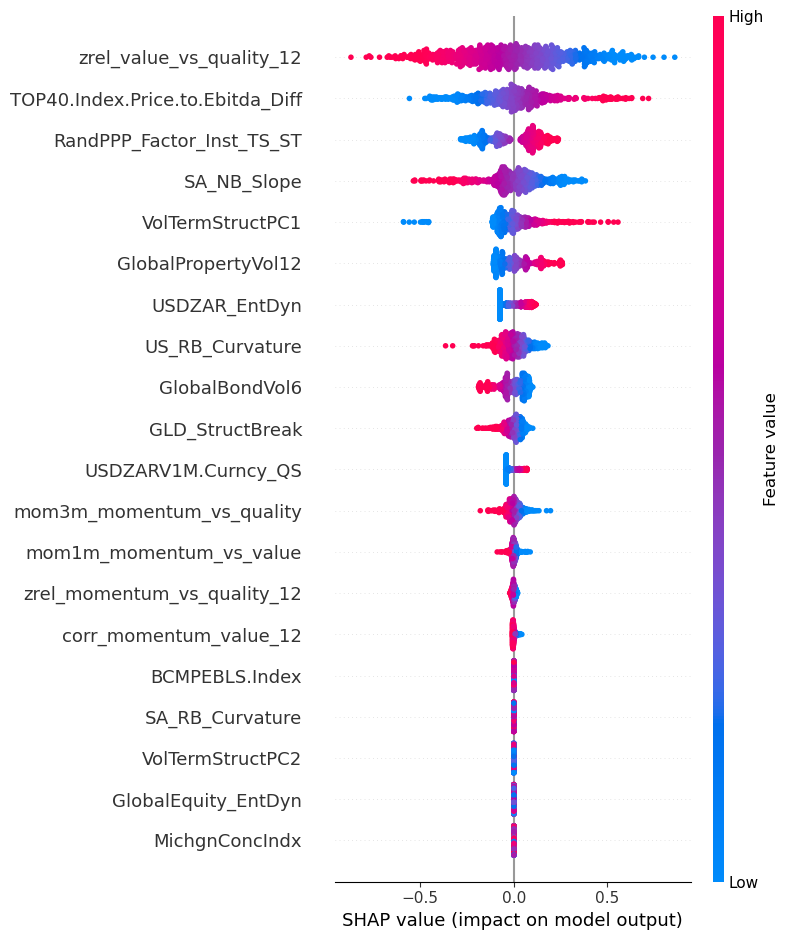


Done. Metrics summary written to: C:\Users\ccwis\OneDrive\Documents\1. MEng - Data Science\Project\factor_timing\legacy\results\model_outputs\metrics_summary.csv


In [15]:
# ============================================
# Run every factor pair
# ============================================
all_results = {}
for pair in FACTOR_PAIRS:
    all_results[pair] = run_pipeline(pair)
    plot_pair_diagnostics(all_results[pair])

print("\nDone. Metrics summary written to:", METRICS_PATH)